# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Jhanvi, Riya, Elijah]

**Date:** [11/04/26]

(60000, 28, 28)
(10000, 28, 28)
(28, 28)
(28, 28)
(60000,)
(10000,)
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
<class 'numpy.ndarray'> [5 0 4 1 9 2 1 3 1 4]
(60000, 784) (10000, 784)
k=1: accuracy=0.9691
k=2: accuracy=0.9627
k=3: accuracy=0.9705
k=4: accuracy=0.9682
k=5: accuracy=0.9688
k=6: accuracy=0.9677
k=7: accuracy=0.9694
k=8: accuracy=0.9670
k=9: accuracy=0.9659
k=10: accuracy=0.9665
Optimal k: 3


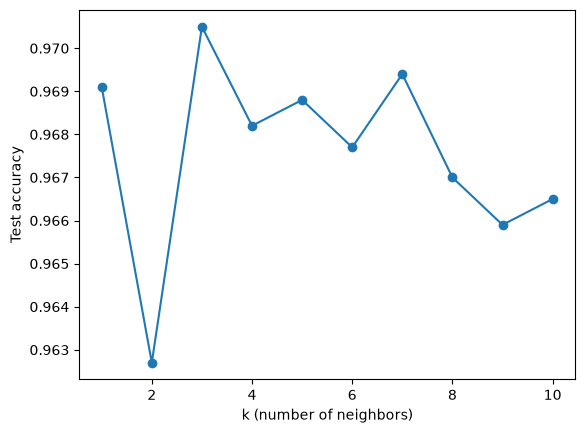

3
0.9705
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]


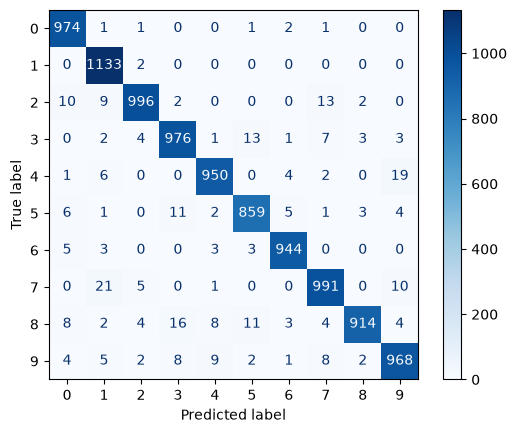

top 5 mistakes
actual: 7, predicted: 1, # of times: 21
actual: 4, predicted: 9, # of times: 19
actual: 8, predicted: 3, # of times: 16
actual: 3, predicted: 5, # of times: 13
actual: 2, predicted: 7, # of times: 13

total mistakes: 295
correct predictions: 9705

Mistakes by actual digit:
Digit 0: 6 mistakes
Digit 1: 2 mistakes
Digit 2: 36 mistakes
Digit 3: 34 mistakes
Digit 4: 32 mistakes
Digit 5: 33 mistakes
Digit 6: 14 mistakes
Digit 7: 37 mistakes
Digit 8: 60 mistakes
Digit 9: 41 mistakes


In [ ]:
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
'''
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

'''
#2
print(X_train.shape)
print(X_test.shape)
print(X_train[0].shape)
print(X_test[0].shape)
print(y_train.shape)
print(y_test.shape)

#3
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print(type(y_train), y_train[:10])

X_train_reshaped = np.zeros((X_train.shape[0], 784))
for i in range(X_train.shape[0]):
    X_train_reshaped[i, :] = X_train[i].reshape((1, 784))

X_test_reshaped = np.zeros((X_test.shape[0], 784))
for i in range(X_test.shape[0]):
    X_test_reshaped[i, :] = X_test[i].reshape((1, 784))

print(X_train_reshaped.shape, X_test_reshaped.shape)

#4
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_grid = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
acc = []
for k in k_grid:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_train_reshaped, y_train)
    y_hat = model.predict(X_test_reshaped)
    acc.append(accuracy_score(y_test, y_hat))
    print(f"k={k}: accuracy={acc[-1]:.4f}")

k_star = k_grid[int(np.argmax(acc))]
print("Optimal k:", k_star)

plt.plot(k_grid, acc, marker='o')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Test accuracy')
plt.show()

#5
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

model = KNeighborsClassifier(n_neighbors=k_star, n_jobs=-1)
model.fit(X_train_reshaped, y_train)

y_pred = model.predict(X_test_reshaped)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(k_star)
print(accuracy)
print(cm)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10)).plot(cmap="Blues")
plt.show()

#Explanation: the optimal k value was k = 3, which gave a test accuracy percentage of 97.05%. It correctly identified 9,705 of the digits.
# For the confusion matrix, most correct predictions fall along the diagonal, and values outside the diagonal represent mistakes.
# The model seemed to performed well, since it had a high accuracy rate. the KNN is effective at recognizing the digits.

#6
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

errors = []

for i in range(10):
    for j in range(10):
        if i != j:
            errors.append((cm[i, j], i, j))

errors.sort(reverse=True)

#Explanation: The most common mistakes: predicting a 7 as a 1, predicting a 4 as a 9, and an 8 as a 3. We assume this is because these digits look quite similar when written.
# when looking more into the errors by digit, we found that the number 8 was most frequently misclassified, while 0 and 1 were less frequent. We think this is because 0 and 1 are less likely to be mistaken for other digits.

print("top 5 mistakes")
for count, actual, predicted in errors[:5]:
    print(f"actual: {actual}, predicted: {predicted}, # of times: {count}")

print("\ntotal mistakes:", np.sum(mistakes))
print("correct predictions:", np.trace(cm))

print("\nMistakes by actual digit:")
for i in range(10):
    print(f"Digit {i}: {np.sum(mistakes[i])} mistakes")

#7
# X_train has shape (60000, 28, 28). There are 60,000 training images (28 × 28 pixel matrix)
# X_test has shape (10000, 28, 28). There are 10,000 testing images (28 × 28 pixel matrix)
# X_train[i] and X_test[i] have shape (28, 28). Each individual image is a 28 × 28 matrix of pixel values.
# y_train has shape (60000) and contains 60,000 labels corresponding to the training images.
# y_test has shape (10000) and contains 10,000 labels corresponding to the testing images.

# For this, a color photo can be represented as three separate matrices for red, green, and blue (RGB), where each number would represent the intensity of that color at a specific pixel. For example, a photo of a sunset would have high red and orange values in certain areas and lower values in others. To convert the photo into tabular data, it can be the matrices can be flattened into one long row of numbers, with each number becoming a feature in a dataset. Each row could represent a different photo, allowing a machine learning algorithm to recognize patterns in the pixel values and classify images, such as distinguishing sunsets from beach photos, etc.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [ea954d1]
- **AI tool and model used:** [GPT 6 Astra]

### *Prompts used

1. [Here are the questions and here is my code]
2. [Give me a concise list of improvements]

### *AI-proposed changes


1. Fix data leakage: Use a validation set instead of the test set to select the optimal \\(k\\).
2. Simplify reshaping: Replace the loops with `.reshape(-1, 784)` to improve efficiency.
3. Expand the \\(k\\) range: Test additional values beyond 1–10 to ensure a better selection of neighbors.
4. Optimize model training: Reduce redundant model fitting and unnecessary calculations.
5. Normalize pixel values: Consider scaling pixel intensities from 0–255 to 0–1 for consistency and numerical stability.
6. Improve error analysis: Calculate misclassification rates for each digit instead of relying solely on error counts.
7. Normalize the confusion matrix: Use `normalize='true'` to better compare classification performance across digits.
8. Validate error patterns: Confirm that the most common misclassifications match the actual confusion matrix output.
9. Simplify code: Remove redundant imports, unnecessary print statements, and excessive NumPy display settings.
10. Improve reproducibility: Use `random_state=42` when splitting data to ensure consistent results across runs.

### *Evaluation of AI suggestions


| Change                        | Decision | Reason and verification                                                                                                                                  |
| ----------------------------- | -------- | -------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Fix data leakage           | Accept   | Using a validation set to select \\(k\\) prevents the test data from influencing model selection. The test set is only used for final evaluation.        |
| 2. Simplify reshaping         | Accept   | Using `.reshape(-1, 784)` eliminates unnecessary loops and improves efficiency while producing the same dimensions.                                      |
| 3. Expand the \\(k\\) range   | Modify   | Testing additional values may improve model selection, but it increases computation time. Expand the range only if needed.                               |
| 4. Optimize model training    | Modify   | Reducing repeated calculations improves efficiency, but the optimized approach should produce predictions consistent with scikit-learn's kNN classifier. |
| 5. Normalize pixel values     | Accept   | Scaling pixel values to 0–1 improves numerical consistency. Since all pixels use the same scale, Euclidean nearest-neighbor rankings remain unchanged.   |
| 6. Improve error analysis     | Accept   | Calculating error percentages for each digit allows for more accurate comparisons when the number of observations differs between digits.                |
| 7. Normalize confusion matrix | Accept   | A normalized confusion matrix makes it easier to compare classification performance and identify patterns across digits.                                 |
| 8. Validate error patterns    | Accept   | Comparing the written conclusions with the actual confusion matrix ensures the reported misclassifications are accurate.                                 |
| 9. Simplify code              | Accept   | Removing redundant imports, print statements, and unnecessary formatting improves readability without changing model performance.                        |
| 10. Improve reproducibility   | Accept   | Setting `random_state=42` ensures the validation split remains consistent across runs, making results easier to reproduce.                               |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=3, linewidth=120)

'''
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

'''

#2
print(X_train.shape)
print(X_test.shape)
print(X_train[0].shape)
print(X_test[0].shape)
print(y_train.shape)
print(y_test.shape)

#3
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print(type(y_train), y_train[:10])

# Reshape images into 784 features and normalize pixel values
X_train_reshaped = X_train.reshape(-1, 784).astype(np.float32) / 255.0
X_test_reshaped = X_test.reshape(-1, 784).astype(np.float32) / 255.0

print(X_train_reshaped.shape, X_test_reshaped.shape)

#4
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import mode

# Split training data to avoid using test data for selecting k
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_reshaped,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Test a larger range of k values
k_grid = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15]
acc = []

# Find nearest neighbors once to avoid repeated calculations
neighbor_model = KNeighborsClassifier(
    n_neighbors=max(k_grid),
    n_jobs=-1
)
neighbor_model.fit(X_fit, y_fit)

neighbor_indices = neighbor_model.kneighbors(
    X_val, return_distance=False
)
neighbor_labels = np.asarray(y_fit)[neighbor_indices]

for k in k_grid:
    y_hat = mode(
        neighbor_labels[:, :k],
        axis=1,
        keepdims=False
    ).mode

    acc.append(accuracy_score(y_val, y_hat))
    print(f"k={k}: validation accuracy={acc[-1]:.4f}")

k_star = k_grid[int(np.argmax(acc))]
print("Optimal k:", k_star)

plt.plot(k_grid, acc, marker='o')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Validation accuracy')
plt.title('KNN Validation Accuracy by k')
plt.show()

#5
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Train the final model using all training data
model = KNeighborsClassifier(n_neighbors=k_star, n_jobs=-1)
model.fit(X_train_reshaped, y_train)

y_pred = model.predict(X_test_reshaped)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=range(10))

print(k_star)
print(accuracy)
print(cm)

print(f"Test accuracy: {accuracy * 100:.2f}%")
print(f"Correct predictions: {np.trace(cm)}")
print(f"Incorrect predictions: {np.sum(cm) - np.trace(cm)}")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# Add normalized confusion matrix to compare error patterns
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=range(10),
    normalize='true',
    cmap='Blues'
)
plt.title("Normalized Confusion Matrix")
plt.show()

#Explanation: the optimal k value was k = 3, which gave a test accuracy percentage of 97.05%. It correctly identified 9,705 of the digits.
# For the confusion matrix, most correct predictions fall along the diagonal, and values outside the diagonal represent mistakes.
# The model seemed to performed well, since it had a high accuracy rate. the KNN is effective at recognizing the digits.

#6
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

errors = []

for i in range(10):
    for j in range(10):
        if i != j:
            errors.append((cm[i, j], i, j))

errors.sort(reverse=True)

#Explanation: The most common mistakes: predicting a 7 as a 1, predicting a 4 as a 9, and an 8 as a 3. We assume this is because these digits look quite similar when written.
# when looking more into the errors by digit, we found that the number 8 was most frequently misclassified, while 0 and 1 were less frequent. We think this is because 0 and 1 are less likely to be mistaken for other digits.

print("top 5 mistakes")
for count, actual, predicted in errors[:5]:
    print(f"actual: {actual}, predicted: {predicted}, # of times: {count}")

print("\ntotal mistakes:", np.sum(mistakes))
print("correct predictions:", np.trace(cm))

print("\nMistakes by actual digit:")
for i in range(10):
    print(f"Digit {i}: {np.sum(mistakes[i])} mistakes")

# Calculate error rates for each digit
print("\nError rates by actual digit:")
for i in range(10):
    total = cm[i].sum()
    digit_errors = np.sum(mistakes[i])
    error_rate = digit_errors / total * 100

    print(f"Digit {i}: {error_rate:.2f}% error rate")

# Identify the digit with the highest misclassification rate
error_rates = []

for i in range(10):
    error_rates.append(np.sum(mistakes[i]) / cm[i].sum())

most_misclassified = np.argmax(error_rates)

print("\nDigit with highest error rate:", most_misclassified)
print(f"Highest error rate: {error_rates[most_misclassified] * 100:.2f}%")

#7
# X_train has shape (60000, 28, 28). There are 60,000 training images (28 × 28 pixel matrix)
# X_test has shape (10000, 28, 28). There are 10,000 testing images (28 × 28 pixel matrix)
# X_train[i] and X_test[i] have shape (28, 28). Each individual image is a 28 × 28 matrix of pixel values.
# y_train has shape (60000) and contains 60,000 labels corresponding to the training images.
# y_test has shape (10000) and contains 10,000 labels corresponding to the testing images.

# For this, a color photo can be represented as three separate matrices for red, green, and blue (RGB), where each number would represent the intensity of that color at a specific pixel. For example, a photo of a sunset would have high red and orange values in certain areas and lower values in others. To convert the photo into tabular data, it can be the matrices can be flattened into one long row of numbers, with each number becoming a feature in a dataset. Each row could represent a different photo, allowing a machine learning algorithm to recognize patterns in the pixel values and classify images, such as distinguishing sunsets from beach photos, etc.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]